In [1]:
import yaml
from datetime import datetime, timezone

import pytz
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn, no_grad, from_numpy
import mlflow
from  mlflow.models import infer_signature

from ml.models import EnsembleComponent, DeepEnsemble
from ml.data import QuantumJumpDataset, add_feature_noise
from ml.train import DeepEnsembleTrainer
from ml.loss import RMSELoss
from ml.types import LossType
from ml.eval import compute_test_error

# Set matplotlib to use TeX for rendering
matplotlib.rcParams.update({"font.size": 16})
plt.rcParams["figure.dpi"] = 125 # set fig resolution

plt.rcParams.update({"text.usetex": True, "font.family": "Helvetica"})

/home/amanuelant/.local/lib/python3.10/site-packages/pymc_marketing/mlflow.py:185: FutureWarning: This functionality is experimental and subject to change. If you encounter any issues or have suggestions, please raise them at: https://github.com/pymc-labs/pymc-marketing/issues/new
  warnings.warn(warning_msg, FutureWarning, stacklevel=1)
/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/pyfunc/utils/data_validation.py:186: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


In [2]:
with open("ensemble_train.yaml", "r") as file:
    config = yaml.safe_load(file)

In [3]:
run_id = config["best_run_id"] 
run = mlflow.get_run(run_id)
parent_run = mlflow.get_run(run.data.tags.get("mlflow.parentRunId"))
run_params = run.data.params
parent_run_params = parent_run.data.params

In [12]:
X_train = np.load("../train_val_data/estimation_data/train/1D/taus.npy")[
    :40_000
]
X_train.shape

(40000, 48)

In [13]:
np.unravel_index(np.argmax(X_train), X_train.shape)

(12201, 39)

In [16]:
print(X_train[np.unravel_index(np.argmax(X_train), X_train.shape)[0]])

[8.54891101e+00 1.81530232e+01 3.53864466e+01 2.22495445e+01
 5.18687909e+00 6.66253758e+01 1.43779747e+01 7.77563114e+00
 1.06038993e+01 9.95279067e+00 3.18326696e+01 4.77652523e+01
 2.10691628e+01 1.28441347e+01 1.25141687e+02 4.45923765e+01
 1.69492023e+02 5.83369396e+00 1.39415055e+02 9.26534921e+00
 4.19625344e-01 6.53361064e+01 5.40057921e+01 1.66855099e+01
 7.69228055e+00 3.53060784e+01 9.72802649e+01 5.81766300e+01
 1.87106200e+01 4.00245120e+01 2.33833237e+00 1.58875387e+01
 5.99104050e+00 2.15760988e+01 4.26269370e+01 7.17193810e+01
 7.14855409e+01 2.11465094e+01 1.33743609e+01 1.65836294e+03
 5.88700538e+01 1.64450363e+01 4.19869473e+01 6.63515432e+01
 2.19366872e+01 7.65248758e-01 5.94125157e+00 3.19621390e+01]


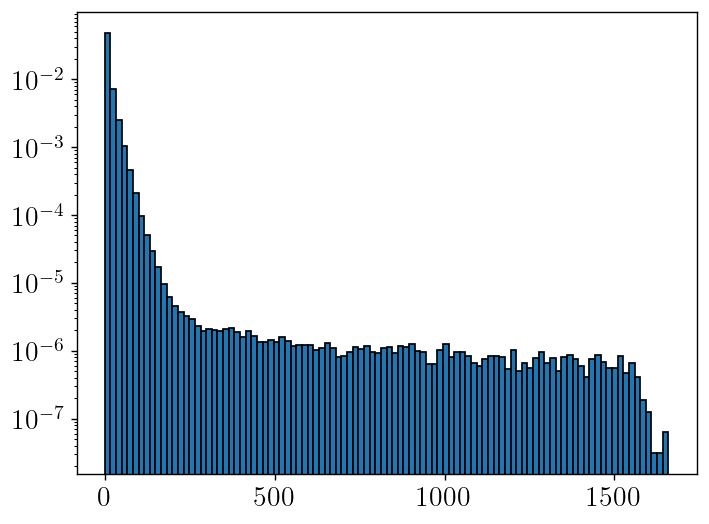

In [22]:
plt.yscale("log")
plt.hist(X_train.flatten(), bins=100, density=True, edgecolor='black');

In [ ]:
fraction = float(parent_run_params["fraction"])

label_noise_std = float(parent_run_params["label_noise_std"])
feature_noise_std = float(parent_run_params["feature_noise_std"])
test_set_feature_noise_std = float(parent_run_params["test_set_feature_noise_std"])
seed = int(parent_run_params["seed"])

train_set_size = int(3_200_000 * fraction)
val_set_size = int(800_000 * fraction)

X_train = np.load("../train_val_data/estimation_data/train/1D/taus.npy")[
    :train_set_size
]

y_train = np.load("../train_val_data/estimation_data/train/1D/deltas.npy").reshape(
    -1, 1
)[:train_set_size]


X_val = np.load("../train_val_data/estimation_data/val/1D/taus.npy")[:val_set_size]


y_val = np.load("../train_val_data/estimation_data/val/1D/deltas.npy").reshape(-1, 1)[
    :val_set_size
]


print(f"Shape of train data: {X_train.shape}.")
print(f"Shape of train labels: {y_train.shape}.")

print(f"Shape of val data: {X_val.shape}.")
print(f"Shape of val labels: {y_val.shape}.")


train_dataset = QuantumJumpDataset(
    X_train,
    y_train,
    feature_noise_std=feature_noise_std,
    label_noise_std=label_noise_std,
    seed=seed
)
val_dataset = QuantumJumpDataset(
    X_val,
    y_val,
    feature_noise_std=feature_noise_std,
    label_noise_std=label_noise_std,
    seed=seed
)

Shape of train data: (32000, 48).
Shape of train labels: (32000, 1).
Shape of val data: (8000, 48).
Shape of val labels: (8000, 1).


In [5]:
num_models = config["num_components"]

hidden_dims = list(map(int, run_params["hidden_layer_sizes"].strip("[]").split(',')))

models = [
    EnsembleComponent(
        num_bins=int(run_params["num_bins"]),
        max_val=100,
        min_val=0,
        init_sigma=0.1,
        hidden_dims=hidden_dims,
        output_dim=1,
        activation=nn.ReLU,
        dropout=float(run_params["dropout"]),
    )
    for _ in range(num_models)
]

ensemble = DeepEnsemble(models=models)

In [6]:
if "early_stopping_epoch" in run.data.metrics:
    num_epochs = int(run.data.metrics["early_stopping_epoch"])
else:
    num_epochs = int(run_params["num_epochs"])

trainer = DeepEnsembleTrainer(
    ensemble_model=ensemble,
    lr=float(run_params["lr"]),
    weight_decay=0,
    num_epochs=num_epochs,
    batch_size=int(run_params["batch_size"]),
    beta1=float(run_params["beta1"]),
    beta2=float(run_params["beta2"]),
    loss_fn=nn.GaussianNLLLoss,
    val_metric_type=LossType["rmse"],
    device="cuda",
    use_adversarial=config["adversarial"]
)

In [ ]:
# get current time in UTC
utc_dt = datetime.now(timezone.utc)

# convert to US Eastern Time
est_dt = utc_dt.astimezone(pytz.timezone("US/Eastern"))

# format to 12-hour time with AM/PM
est_str = est_dt.strftime("%B/%d/%Y %I:%M:%S %p")

if config["use_current_date"]:
    mlflow.set_experiment(f"ensemble - {est_str} - TLS")
else:
    mlflow.set_experiment("Deep Ensemble - TLS")

Traceback (most recent call last):
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 356, in search_experiments
    exp = self._get_experiment(exp_id, view_type)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 454, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 1595, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 1588, in _read_helper
    result = read_yaml(root, file_name)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/utils/yaml_utils.py", line 107, in read_yaml
    raise MissingConfigException(f"Yaml file '{file_path}' does not exist.")
mlflow.exceptions.MissingCon

Loading model with uri: runs:/02e336fd13d748769fdb1c5a08180a6b/ensemble_model


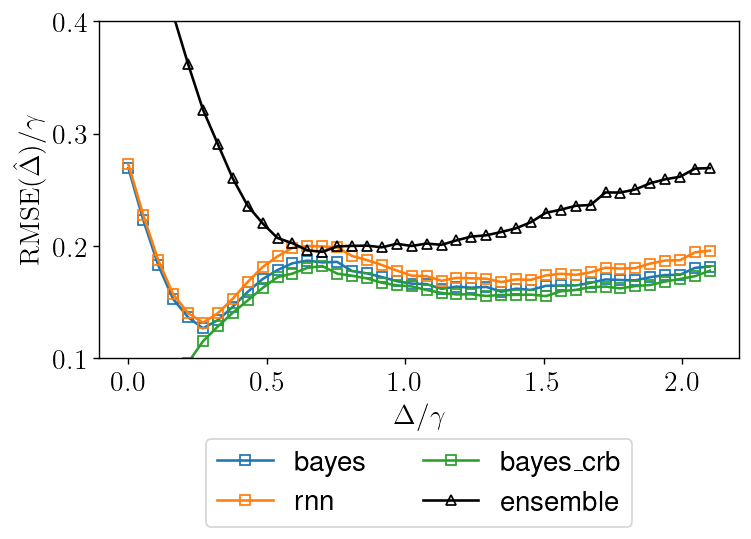

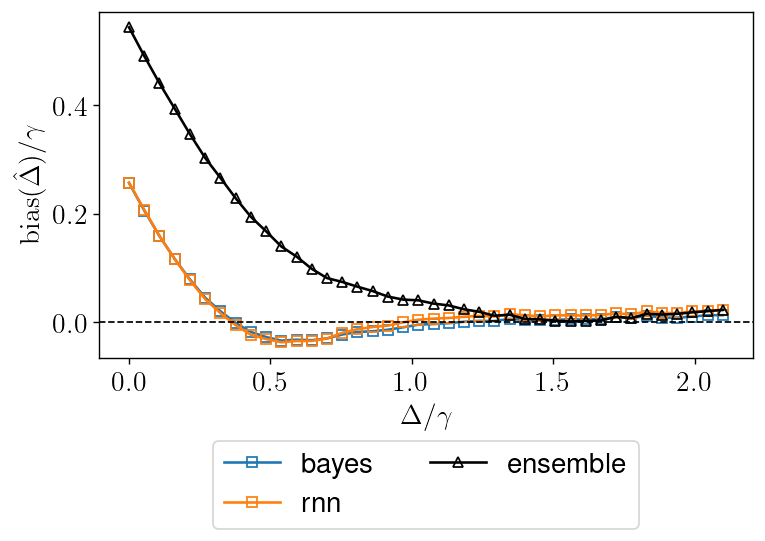

In [8]:
with mlflow.start_run() as ensemble_run:
    mlflow.log_param("single_model_run_id", parent_run.info.run_id)
    mlflow.log_param("adversarial", config["adversarial"])
    mlflow.log_param("ensemble_size", config["num_components"])
    mlflow.log_params(parent_run_params)

    if "early_stopping_epoch" in run.data.metrics:
        mlflow.log_param("early_stopping_epoch", int(run.data.metrics["early_stopping_epoch"]))
    
    trainer.train(
        train_dataset=train_dataset, val_dataset=val_dataset, epochs_per_val=1
    )

    mlflow.pytorch.log_model(
        ensemble,
        name="ensemble_model",
        signature=infer_signature(train_dataset[0][0].numpy()),
    )

    run_id = ensemble_run.info.run_id
    model_uri = f"runs:/{run_id}/ensemble_model"

    device = "cuda" if torch.cuda.is_available() else "cpu"

    print(f"Loading model with uri: {model_uri}")

    selected_model = mlflow.pytorch.load_model(model_uri=model_uri)
    selected_model = selected_model.to(device)

    X_test = np.load(
        "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
    )

    y_test = np.load(
            "../test-trajectories/1D-delta/validation-deltas-1D-delta-nsets-10000.npy"
        ).reshape(-1, 1)

    if test_set_feature_noise_std > 0:
            X_test = add_feature_noise(X_test, test_set_feature_noise_std, seed)
        
    elif feature_noise_std > 0:
        X_test = add_feature_noise(X_test, feature_noise_std, seed)

    X_test = from_numpy(X_test).float().to(device)
    y_test = from_numpy(y_test).float().to(device)

    selected_model.eval()
    rmse_loss = RMSELoss()

    rmses, biases = compute_test_error(selected_model, rmse_loss, X_test, y_test)

    paper_rmses = dict(np.load("../results_cache/carlos_rmses.npz"))
    paper_biases = dict(np.load("../results_cache/carlos_biases.npz"))

    deltalist, _ = paper_rmses.pop("deltalist"), paper_biases.pop("deltalist")
    del paper_rmses["classical"] 
    del paper_rmses["classical_crb"]
    #del paper_rmses["bayes_crb"]
    del paper_biases["classical"] 

    fig, ax = plt.subplots()
    for key, value in paper_rmses.items():
        ax.plot(
            deltalist,
            value,
            marker="s",
            markerfacecolor="none",
            linestyle="-",
            label=f"{key}",
        )

    ax.plot(
        y_test.cpu().numpy().flatten(),
        rmses,
        marker="^",
        markerfacecolor="none",
        linestyle="-",
        label="ensemble",
        color="black",
    )

    mlflow.log_metric("mean_test_rmse", np.array(rmses).mean())

    ax.set_xlabel(r"$\Delta/\gamma$")
    ax.set_ylabel(r"$\textrm{RMSE}(\hat{\Delta})/\gamma$")

    ax.set_ylim(0.1, 0.4)
    ax.legend(fancybox=True, bbox_to_anchor=(0.5, -0.2), ncol=2, loc="upper center")
    fig.tight_layout()
    mlflow.log_figure(fig, "rmses.png")

    fig, ax = plt.subplots()
    for key, value in paper_biases.items():
        ax.plot(
            deltalist,
            value,
            marker="s",
            markerfacecolor="none",
            linestyle="-",
            label=f"{key}",
        )

    ax.plot(
        y_test.cpu().numpy().flatten(),
        biases,
        marker="^",
        markerfacecolor="none",
        linestyle="-",
        color="black",
        label="ensemble",
    )
    ax.axhline(
        y=0, color="black", linestyle="--", linewidth=1
    )  # horizontal line at bias = 0

    ax.set_xlabel(r"$\Delta/\gamma$")
    ax.set_ylabel(r"$\textrm{bias}(\hat{\Delta})/\gamma$")
    #ax.set_ylim(-0.1, 0.4)
    ax.legend(fancybox=True, bbox_to_anchor=(0.5, -0.2), ncol=2, loc="upper center")
    fig.tight_layout()
    mlflow.log_figure(fig, "biases.png")
    

mlflow.end_run()  # end the run

In [9]:
preds, errs = [], []

# use no grad or else memory consumptions is large
with no_grad():
    for trajectories, delta in zip(X_test, y_test):

        point_ests, vars = selected_model(trajectories.flatten()[:48].unsqueeze(0))
        stds = torch.sqrt(vars)
        preds.append(point_ests.cpu()[0].item())
        #preds.append(torch.exp(point_ests).cpu()[0].item())
        errs.append(stds.cpu()[0].item())



[0.7860816  0.78727456 0.69027368 0.75225407 0.79194967 0.78944377
 0.91421619 0.8321809  0.75657082 0.90229916 0.74484141 1.05746439
 0.9311903  0.81685152 0.8944019  0.98096521 0.84446839 1.00605153
 1.19043414 0.96980777 1.17599724 0.98159712 1.12783014 1.07924748
 0.89699611 1.19096184 1.19891915 1.07972296 1.07931489 1.07740702
 1.07214545 1.06403113 1.24440161 1.2257131  1.13018872 1.10650605
 1.04490639 1.06768495 1.23955828 1.31006293]


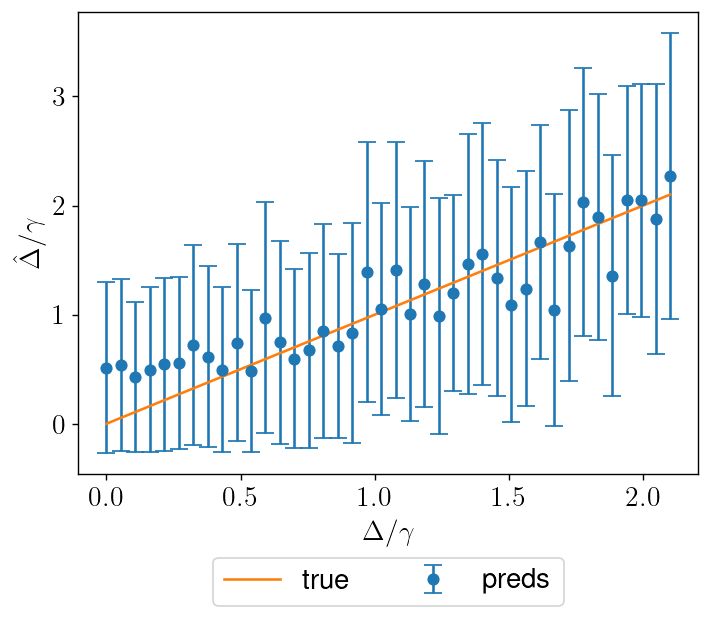

In [10]:
x = y_test.cpu().numpy().flatten()
preds = np.array(preds)
errs_ = 1.96*np.array(errs)
print(errs_)

plt.errorbar(x, preds, yerr=np.array(errs_), fmt='o', capsize=5, label="preds")
plt.plot(x, x, label="true")
#plt.plot(x, preds, marker="o", label="predicted")
#plt.fill_between(x, preds - errs_, preds + errs_, alpha=0.3, facecolor='blue', label=r'$\pm\sigma$')
plt.xlabel(r"$\Delta/\gamma$")
plt.ylabel(r"$\hat{\Delta}/\gamma$")
plt.legend(fancybox=True, bbox_to_anchor=(0.5, -0.15), ncol=2, loc="upper center");